# 15 · Convolutional Neural Networks (CNNs)

Notebook 07 built fully-connected networks (MLPs). They can in principle learn anything, but for **images** they are wasteful and brittle. **Convolutional neural networks** build in two facts about images: nearby pixels belong together, and a cat is a cat wherever it appears in the picture. That design idea powered the deep-learning breakthrough in computer vision.

**What you'll learn**
1. Why MLPs struggle with images
2. The **convolution** operation — 🐍 pure Python → 🔢 NumPy → 📦 PyTorch — and what hand-made filters detect on a real photo
3. **Padding, stride, channels, pooling**, and the output-size formula
4. **Receptive fields** and the three inductive biases (locality, weight sharing, translation equivariance)
5. Training a CNN in PyTorch, and a head-to-head with an MLP — including a **translation test** an MLP fails
6. Looking inside: learned **filters** and **feature maps**
7. Running a trained CNN with our own NumPy code (inference from scratch)
8. Practical tools: **data augmentation**, batch norm, dropout, **transfer learning**, and the classic architectures (LeNet → AlexNet → VGG → ResNet)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, time
import torch
from torch import nn
import torch.nn.functional as F
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); torch.manual_seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))

## 1. Why not just use an MLP on pixels?

An image is a grid of numbers: grayscale = one number per pixel (0 = black, 1 = white); colour = three numbers per pixel (red, green, blue **channels**). An MLP would flatten the grid into one long vector. Three problems:

1. **Too many weights.** A 224×224 colour image has 150,528 inputs. One hidden layer of 1,000 neurons → **150 million weights** in the first layer alone.
2. **No notion of "nearby".** Flattening throws away the 2-D layout. Shuffle the pixels the same way in every image and an MLP learns equally well — it never used the fact that neighbouring pixels are related.
3. **No translation invariance.** A cat in the top-left and a cat in the bottom-right activate completely different input weights. The MLP must learn "cat" separately for every position.

A CNN fixes all three by sliding **small shared filters** across the image.

## 2. The convolution operation

Take a small grid of weights — a **filter** (or **kernel**), e.g. 3×3. Slide it across the image. At each position, multiply the filter by the patch of pixels underneath, element by element, and add up the result. That sum becomes one pixel of the output **feature map**.
$$ \text{out}[i, j] = \sum_{u}\sum_{v} \text{image}[i+u,\, j+v] \cdot \text{kernel}[u, v] \;+\; b $$
(Strictly, this is *cross-correlation*; true convolution flips the kernel first. Deep-learning libraries all use the unflipped version and call it convolution, and since the kernel is learned the difference doesn't matter.)

In [2]:
# 🐍 Pure Python 2-D convolution ("valid": no padding)
def conv2d_python(image, kernel):
    H, W = len(image), len(image[0]); kh, kw = len(kernel), len(kernel[0])
    out = []
    for i in range(H - kh + 1):
        row = []
        for j in range(W - kw + 1):
            s = 0.0
            for u in range(kh):
                for v in range(kw):
                    s += image[i + u][j + v] * kernel[u][v]
            row.append(s)
        out.append(row)
    return out

img_small = [[0, 0, 0, 1, 1, 1]] * 6                              # dark left half, bright right half
vertical_edge = [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]              # responds to dark→bright going left to right
for row in conv2d_python(img_small, vertical_edge):
    print(row)
print("→ large values exactly where the vertical edge is")

[0.0, 3.0, 3.0, 0.0]
[0.0, 3.0, 3.0, 0.0]
[0.0, 3.0, 3.0, 0.0]
[0.0, 3.0, 3.0, 0.0]
→ large values exactly where the vertical edge is


In [3]:
# 🔢 NumPy: extract every 3×3 window at once, then one tensor contraction (no Python loops over pixels)
from numpy.lib.stride_tricks import sliding_window_view
def conv2d_numpy(image, kernel):
    windows = sliding_window_view(image, kernel.shape)            # shape (H−kh+1, W−kw+1, kh, kw)
    return np.einsum("ijuv,uv->ij", windows, kernel)

# 📦 PyTorch: F.conv2d expects (batch, channels, H, W)
from sklearn.datasets import load_sample_image
photo = load_sample_image("china.jpg").mean(axis=2) / 255.0       # 427×640 grayscale photo
k = np.array(vertical_edge, float)
t0 = time.perf_counter(); out_py = conv2d_python(photo.tolist(), k.tolist()); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); out_np = conv2d_numpy(photo, k); t_np = time.perf_counter() - t0
out_t = F.conv2d(torch.tensor(photo)[None, None], torch.tensor(k)[None, None])[0, 0].numpy()
print("pure Python == NumPy == PyTorch:", np.allclose(out_py, out_np), np.allclose(out_np, out_t))
print(f"whole 427×640 photo: pure Python {t_py:.2f} s | NumPy {t_np * 1000:.1f} ms → ~{t_py / t_np:.0f}× faster")

pure Python == NumPy == PyTorch: True True
whole 427×640 photo: pure Python 0.17 s | NumPy 5.3 ms → ~32× faster


### What different filters detect
Before deep learning, people **designed** filters by hand. A CNN **learns** them — and its first layer usually ends up looking much like these:

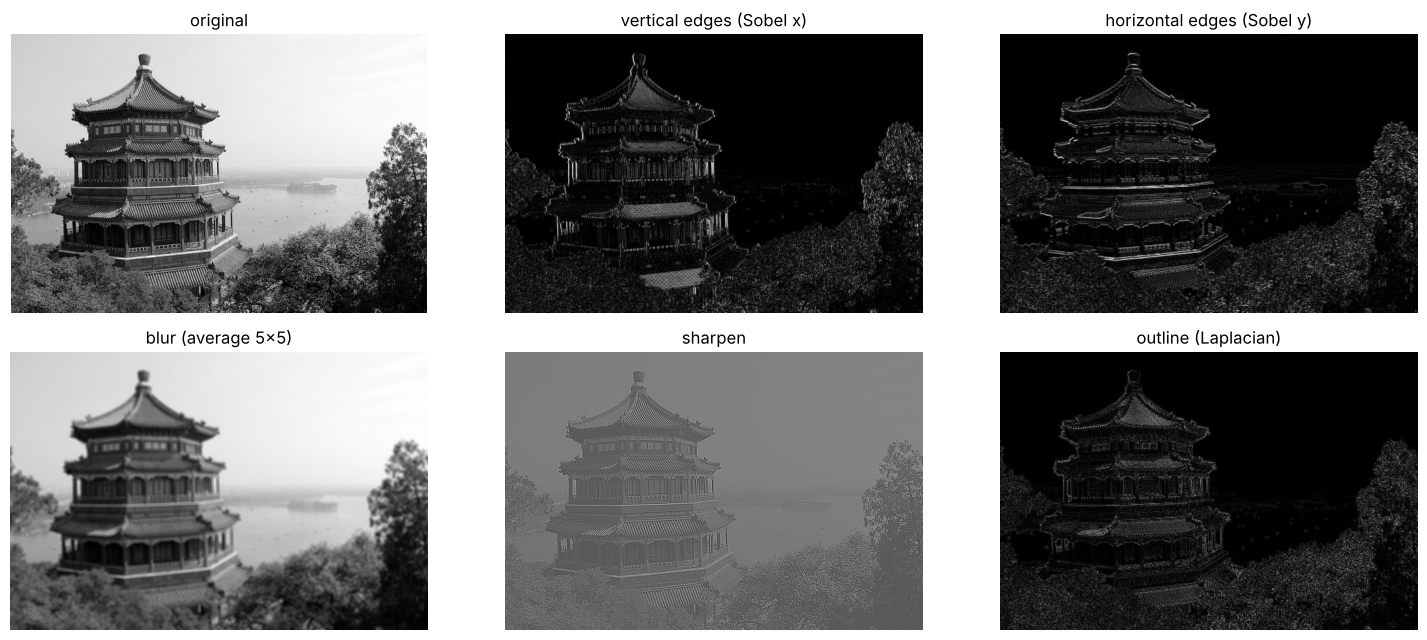

In [4]:
filters = {
    "vertical edges (Sobel x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edges (Sobel y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "blur (average 5×5)": np.ones((5, 5)) / 25,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "outline (Laplacian)": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
axes[0, 0].imshow(photo, cmap="gray"); axes[0, 0].set_title("original"); axes[0, 0].axis("off")
for ax, (name, kern) in zip(axes.ravel()[1:], filters.items()):
    res = conv2d_numpy(photo, kern.astype(float))
    ax.imshow(np.abs(res) if "edge" in name or "outline" in name else res, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Padding, stride, channels and pooling

**Output size.** For input width W, kernel K, padding P (zeros added around the border) and stride S (how far the filter jumps each step):
$$ W_{\text{out}} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1 $$
- **"Same" padding** ($P = (K-1)/2$, S = 1) keeps the size unchanged.
- **Stride 2** halves the size — a cheap way to downsample.

**Channels.** A colour image has 3 input channels; a filter then has shape 3 × K × K and sums over all channels. A conv layer has **many** filters — say 32 — and outputs 32 feature maps (output channels). Weights per layer = out_channels × in_channels × K × K (+ biases) — **independent of image size**.

**Pooling** shrinks feature maps by summarising small windows: **max pooling** (keep the largest value — "is the feature present anywhere here?") or average pooling. It adds a little translation tolerance and cuts computation. **Global average pooling** at the end averages each feature map to a single number.

In [5]:
def out_size(W, K, P=0, S=1): return (W - K + 2 * P) // S + 1

x = torch.randn(1, 3, 32, 32)                                     # one 32×32 colour image
for desc, layer in [("3×3, no padding", nn.Conv2d(3, 16, 3)), ("3×3, padding 1 ('same')", nn.Conv2d(3, 16, 3, padding=1)),
                    ("3×3, stride 2, padding 1", nn.Conv2d(3, 16, 3, stride=2, padding=1)), ("5×5, no padding", nn.Conv2d(3, 16, 5)),
                    ("max-pool 2×2", nn.MaxPool2d(2))]:
    y = layer(x); params = sum(p.numel() for p in layer.parameters())
    K = layer.kernel_size if isinstance(layer.kernel_size, int) else layer.kernel_size[0]
    P = layer.padding if isinstance(layer.padding, int) else layer.padding[0]; S = layer.stride if isinstance(layer.stride, int) else layer.stride[0]
    print(f"{desc:26s} → output {tuple(y.shape)}  formula width {out_size(32, K, P, S)}  params {params}")

3×3, no padding            → output (1, 16, 30, 30)  formula width 30  params 448
3×3, padding 1 ('same')    → output (1, 16, 32, 32)  formula width 32  params 448
3×3, stride 2, padding 1   → output (1, 16, 16, 16)  formula width 16  params 448


5×5, no padding            → output (1, 16, 28, 28)  formula width 28  params 1216
max-pool 2×2               → output (1, 3, 16, 16)  formula width 16  params 0


In [6]:
# 🐍 Max pooling by hand vs PyTorch
def maxpool_python(fm, size=2):
    return [[max(fm[i + u][j + v] for u in range(size) for v in range(size))
             for j in range(0, len(fm[0]) - size + 1, size)] for i in range(0, len(fm) - size + 1, size)]
fm = rng.integers(0, 10, (4, 4)).astype(float)
print(fm, "\n→ max-pooled:", maxpool_python(fm.tolist()), "| PyTorch:", F.max_pool2d(torch.tensor(fm)[None, None], 2)[0, 0].tolist())

[[8. 6. 5. 2.]
 [3. 0. 0. 0.]
 [1. 8. 6. 9.]
 [5. 6. 9. 7.]] 
→ max-pooled: [[8.0, 5.0], [8.0, 9.0]] | PyTorch: [[8.0, 5.0], [8.0, 9.0]]


## 4. Receptive fields and the three inductive biases

Each output pixel of a 3×3 conv sees a 3×3 patch. Stack two 3×3 layers and an output pixel sees 5×5 of the input; three layers → 7×7; pooling and strides grow it faster. Deep layers therefore "see" large regions and can detect **parts** and **objects**, built from the **edges** and **textures** found by early layers. This hierarchy — edges → textures → parts → objects — is what CNNs learn.

**Inductive biases** (assumptions built into the architecture):
1. **Locality:** a filter only looks at a small neighbourhood.
2. **Weight sharing:** the same filter is used at every position → far fewer weights.
3. **Translation equivariance:** shift the input and the feature map shifts the same way. Add pooling and you get (approximate) **invariance** — the final answer doesn't care where the object was.

conv(shift(x)) == shift(conv(x)): True


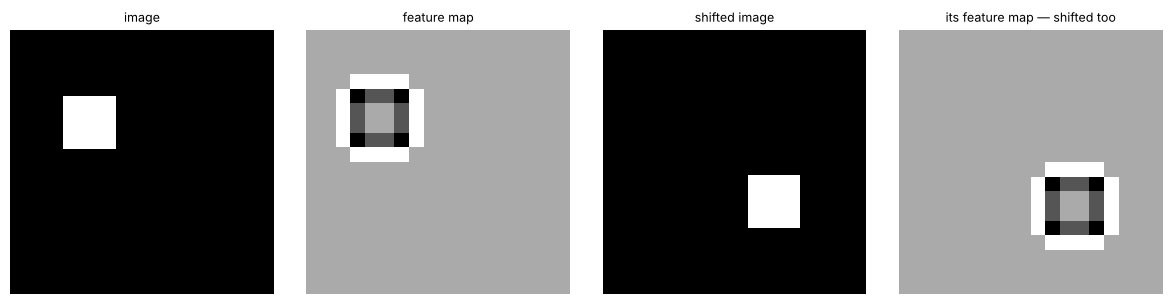

In [7]:
# Equivariance, demonstrated: convolving a shifted image = shifting the convolved image
img = np.zeros((20, 20)); img[5:9, 4:8] = 1.0                     # a small square
shifted = np.roll(img, (6, 7), axis=(0, 1))
k = filters["outline (Laplacian)"].astype(float)
a1, a2 = conv2d_numpy(img, k), conv2d_numpy(shifted, k)
print("conv(shift(x)) == shift(conv(x)):", np.allclose(np.roll(a1, (6, 7), axis=(0, 1)), a2))
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, (t, m) in zip(ax, [("image", img), ("feature map", a1), ("shifted image", shifted), ("its feature map — shifted too", a2)]):
    a.imshow(m, cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Training a CNN — and a fair fight with an MLP

### 5.1 Handwritten digits
scikit-learn's digits: 1,797 images of 8×8 pixels. Small, so everything trains in seconds on a CPU.

MLP: 9,610 params → test acc 0.972
CNN: 5,130 params → test acc 0.930


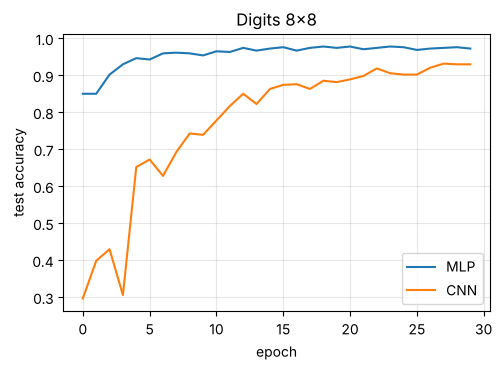

In [8]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
Xd = (digits.images / 16.0).astype(np.float32); yd = digits.target
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.3, random_state=0, stratify=yd)
to_t = lambda X: torch.tensor(X)[:, None]                         # add the channel dimension → (N, 1, H, W)

def train_model(model, X, y, Xv, yv, epochs=30, lr=3e-3, batch=64, wd=1e-4, augment=None, verbose=False):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    Xt, yt = torch.as_tensor(X), torch.as_tensor(y); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(yt))
        for i in range(0, len(yt), batch):
            idx = perm[i:i + batch]; xb = Xt[idx]
            if augment is not None: xb = augment(xb)
            loss = F.cross_entropy(model(xb), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(accuracy(model, Xv, yv))
        if verbose and ep % 5 == 4: print(f"epoch {ep + 1}: val acc {hist[-1]:.3f}")
    return hist

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(torch.as_tensor(X)).argmax(1) == torch.as_tensor(y)).float().mean().item()

def n_params(m): return sum(p.numel() for p in m.parameters())

class SmallCNN(nn.Module):
    def __init__(self, n_classes=10, c1=16, c2=32):
        super().__init__()
        self.conv1 = nn.Conv2d(1, c1, 3, padding=1)   # → c1 × H × W
        self.conv2 = nn.Conv2d(c1, c2, 3, padding=1)  # → c2 × H/2 × W/2
        self.head = nn.Linear(c2, n_classes)
    def features(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)    # conv → ReLU → pool
        x = F.relu(self.conv2(x))
        return x
    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3))                         # global average pooling → one number per channel
        return self.head(x)

mlp = nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10))
cnn = SmallCNN()
h_mlp = train_model(mlp, to_t(Xtr), ytr, to_t(Xte), yte)
h_cnn = train_model(cnn, to_t(Xtr), ytr, to_t(Xte), yte)
print(f"MLP: {n_params(mlp):,} params → test acc {h_mlp[-1]:.3f}")
print(f"CNN: {n_params(cnn):,} params → test acc {h_cnn[-1]:.3f}")
plt.plot(h_mlp, label="MLP"); plt.plot(h_cnn, label="CNN"); plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend(); plt.title("Digits 8×8"); plt.show()

On tiny, centred 8×8 digits the MLP actually does as well or better. With only 64 pixels and every digit roughly centred, there's little for convolutions to exploit, and global average pooling throws away the position information that's useful here. **A CNN is not automatically better.** Its advantages show up on bigger images and when **objects move**.

### 5.2 The translation test
We generate 32×32 images of three shapes — **circle, square, triangle** — at random sizes. **Training images only have shapes in the top-left quarter.** Test images put them **anywhere**. Can the model recognise a shape in a place it has never seen one?

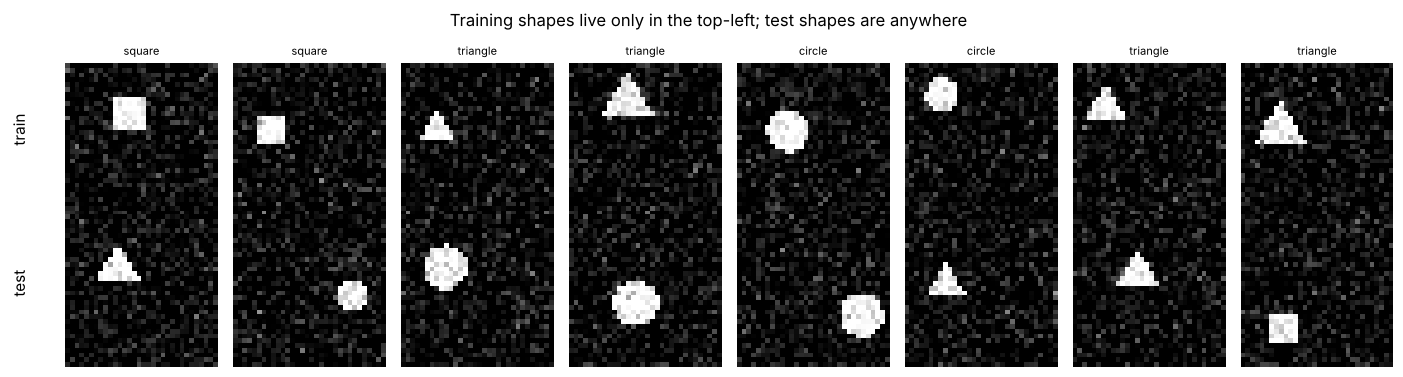

In [9]:
def draw_shape(kind, size, cx, cy, N=32):
    yy, xx = np.mgrid[0:N, 0:N]
    if kind == 0:   m = (xx - cx) ** 2 + (yy - cy) ** 2 <= size ** 2                          # circle
    elif kind == 1: m = (np.abs(xx - cx) <= size * 0.85) & (np.abs(yy - cy) <= size * 0.85)    # square
    else:           m = (yy - cy <= size * 0.8) & (yy - cy >= -size) & (np.abs(xx - cx) <= (yy - cy + size) * 0.6)  # triangle
    return m.astype(np.float32)

def make_shapes(n, region, seed):
    r = np.random.default_rng(seed); X = np.zeros((n, 32, 32), np.float32); y = r.integers(0, 3, n)
    for i in range(n):
        s = r.uniform(3, 5.5)
        lo, hi = (6, 14) if region == "top-left" else (6, 26)
        X[i] = draw_shape(y[i], s, r.uniform(lo, hi), r.uniform(lo, hi)) + r.normal(0, 0.15, (32, 32))
    return np.clip(X, 0, 1), y

Xs_tr, ys_tr = make_shapes(3000, "top-left", 1)
Xs_te_same, ys_te_same = make_shapes(600, "top-left", 2)
Xs_te_any, ys_te_any = make_shapes(600, "anywhere", 3)
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for i, ax in enumerate(axes[0]): ax.imshow(Xs_tr[i], cmap="gray"); ax.set_title(["circle", "square", "triangle"][ys_tr[i]], fontsize=8); ax.axis("off")
for i, ax in enumerate(axes[1]): ax.imshow(Xs_te_any[i], cmap="gray"); ax.axis("off")
axes[0, 0].text(-12, 16, "train", fontsize=11, rotation=90); axes[1, 0].text(-12, 16, "test", fontsize=11, rotation=90)
plt.suptitle("Training shapes live only in the top-left; test shapes are anywhere"); plt.tight_layout(); plt.show()

In [10]:
torch.manual_seed(0)
mlp_s = nn.Sequential(nn.Flatten(), nn.Linear(1024, 256), nn.ReLU(), nn.Linear(256, 3))
cnn_s = SmallCNN(n_classes=3)
train_model(mlp_s, to_t(Xs_tr), ys_tr, to_t(Xs_te_same), ys_te_same, epochs=15)
train_model(cnn_s, to_t(Xs_tr), ys_tr, to_t(Xs_te_same), ys_te_same, epochs=15)
for name, m in [("MLP", mlp_s), ("CNN", cnn_s)]:
    print(f"{name}: {n_params(m):>7,} params | test acc, same region {accuracy(m, to_t(Xs_te_same), ys_te_same):.3f} | "
          f"shapes anywhere {accuracy(m, to_t(Xs_te_any), ys_te_any):.3f}")
print("(chance = 0.333)")

MLP: 263,171 params | test acc, same region 0.803 | shapes anywhere 0.422
CNN:   4,899 params | test acc, same region 0.970 | shapes anywhere 0.967
(chance = 0.333)


The MLP learned "a circle has bright pixels **at these positions**" — useless when the circle moves. The CNN's filters respond to the shape's *edges and corners wherever they are*, and global average pooling makes the final decision position-independent. It also uses far fewer parameters. **This is the power of the right inductive bias.**

## 6. Looking inside the CNN

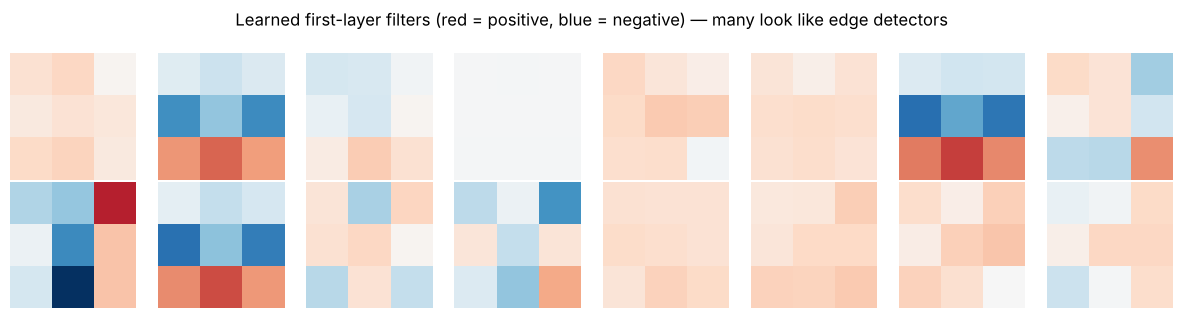

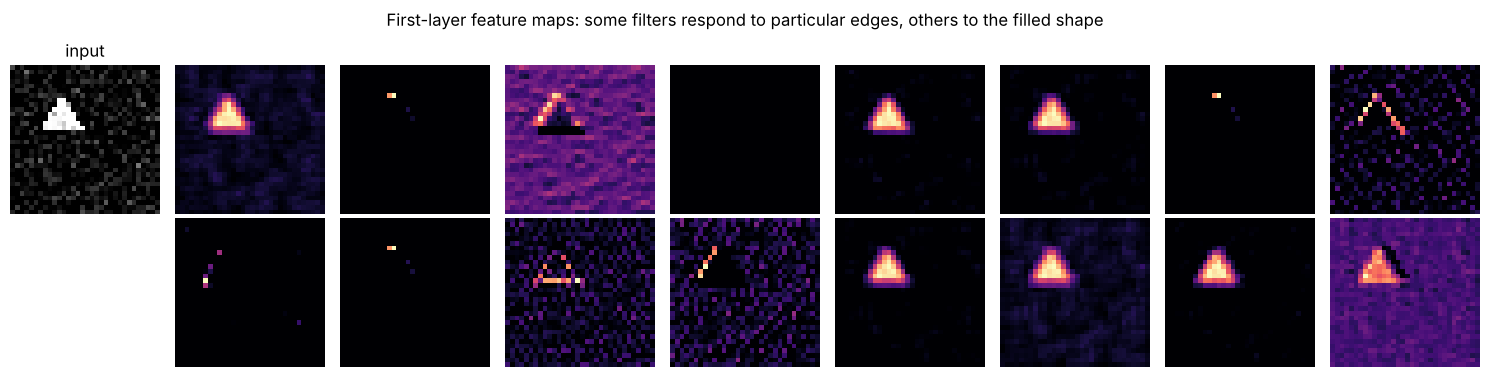

In [11]:
w1 = cnn_s.conv1.weight.detach().numpy()[:, 0]                    # 16 learned 3×3 filters
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, f_ in zip(axes.ravel(), w1):
    ax.imshow(f_, cmap="RdBu_r", vmin=-np.abs(w1).max(), vmax=np.abs(w1).max()); ax.axis("off")
plt.suptitle("Learned first-layer filters (red = positive, blue = negative) — many look like edge detectors"); plt.tight_layout(); plt.show()

i = int(np.where(ys_te_any == 2)[0][0])                           # a test triangle
with torch.no_grad():
    fmaps = F.relu(cnn_s.conv1(to_t(Xs_te_any[i:i + 1])))[0].numpy()
fig, axes = plt.subplots(2, 9, figsize=(15, 3.8))
axes[0, 0].imshow(Xs_te_any[i], cmap="gray"); axes[0, 0].set_title("input"); axes[1, 0].axis("off")
for ax, fm_ in zip(list(axes[0, 1:]) + list(axes[1, 1:]), fmaps):
    ax.imshow(fm_, cmap="magma")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("First-layer feature maps: some filters respond to particular edges, others to the filled shape"); plt.tight_layout(); plt.show()

## 7. 🔢 Running the trained CNN with our own NumPy code

To prove there's no magic inside `nn.Conv2d`, we copy the trained weights into a NumPy implementation of the forward pass and check that it gives exactly the same outputs. A multi-channel convolution is just our `conv2d_numpy` summed over input channels, plus a bias. (Training also needs the backward pass. The gradient of a convolution is itself a convolution — see `dl_from_scratch.py` for a full implementation.)

In [12]:
def conv_layer_numpy(x, W, b, pad=1):
    """x: (C_in, H, W); W: (C_out, C_in, k, k) → (C_out, H, W) with 'same' padding."""
    xp = np.pad(x, ((0, 0), (pad, pad), (pad, pad)))
    win = sliding_window_view(xp, W.shape[2:], axis=(1, 2))           # (C_in, H, W, k, k)
    return np.einsum("chwuv,ocuv->ohw", win, W) + b[:, None, None]

def maxpool_numpy(x, s=2):
    C, H, W = x.shape
    return x[:, :H // s * s, :W // s * s].reshape(C, H // s, s, W // s, s).max(axis=(2, 4))

def cnn_forward_numpy(img, m):
    p = {k: v.detach().numpy() for k, v in m.state_dict().items()}
    x = maxpool_numpy(np.maximum(0, conv_layer_numpy(img[None], p["conv1.weight"], p["conv1.bias"])))
    x = np.maximum(0, conv_layer_numpy(x, p["conv2.weight"], p["conv2.bias"]))
    return x.mean(axis=(1, 2)) @ p["head.weight"].T + p["head.bias"]

logits_np = np.array([cnn_forward_numpy(Xs_te_any[j], cnn_s) for j in range(50)])
cnn_s.eval()
with torch.no_grad(): logits_t = cnn_s(to_t(Xs_te_any[:50])).numpy()
print("NumPy forward pass == PyTorch:", np.allclose(logits_np, logits_t, atol=1e-4), "| predictions agree:", np.mean(logits_np.argmax(1) == logits_t.argmax(1)))

NumPy forward pass == PyTorch: True | predictions agree: 1.0


## 8. Practical tools

### 8.1 Data augmentation
Make more training data by applying label-preserving changes — shifts, flips, small rotations, crops, colour jitter. It's often the single most effective regulariser for image models. Here, random shifts let even a position-sensitive **MLP** generalise to new locations:

In [13]:
def random_shift(xb, max_shift=12):
    out = torch.empty_like(xb)
    for i in range(len(xb)):
        dy, dx = np.random.randint(0, max_shift + 1, 2)            # move right/down into unseen territory
        out[i] = torch.roll(xb[i], shifts=(int(dy), int(dx)), dims=(1, 2))
    return out

torch.manual_seed(0); np.random.seed(0)
mlp_aug = nn.Sequential(nn.Flatten(), nn.Linear(1024, 256), nn.ReLU(), nn.Linear(256, 3))
train_model(mlp_aug, to_t(Xs_tr), ys_tr, to_t(Xs_te_any), ys_te_any, epochs=15, augment=random_shift)
print(f"MLP trained WITH shift augmentation → shapes anywhere: {accuracy(mlp_aug, to_t(Xs_te_any), ys_te_any):.3f}  (without: {accuracy(mlp_s, to_t(Xs_te_any), ys_te_any):.3f})")

MLP trained WITH shift augmentation → shapes anywhere: 0.627  (without: 0.422)


Augmentation helped the MLP a lot, but it's still far behind the CNN (0.97 with about 50× fewer parameters). Learning "the same shape can appear anywhere" from examples is much harder than having it built into the architecture. In practice you use both: a CNN **and** augmentation.

### 8.2 Batch normalisation and dropout
- **BatchNorm** (`nn.BatchNorm2d`) normalises each channel over the batch, then rescales with learned parameters. It makes deep CNNs train faster and more stably and allows higher learning rates.
- **Dropout** randomly zeroes activations during training (notebook 07); in CNNs it's mostly used in the final dense layers.

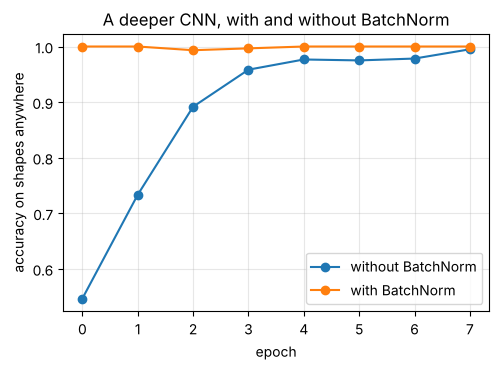

In [14]:
class DeeperCNN(nn.Module):
    def __init__(self, n_classes=3, bn=True):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1)] + ([nn.BatchNorm2d(cout)] if bn else []) + [nn.ReLU()]
            return nn.Sequential(*layers)
        self.body = nn.Sequential(block(1, 16), block(16, 16), nn.MaxPool2d(2), block(16, 32), block(32, 32), nn.MaxPool2d(2), block(32, 64))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, n_classes))
    def forward(self, x): return self.head(self.body(x).mean(dim=(2, 3)))

curves = {}
for bn in [False, True]:
    torch.manual_seed(0)
    m = DeeperCNN(bn=bn)
    curves[f"{'with' if bn else 'without'} BatchNorm"] = train_model(m, to_t(Xs_tr), ys_tr, to_t(Xs_te_any), ys_te_any, epochs=8, lr=3e-3)
for k_, v_ in curves.items(): plt.plot(v_, "o-", label=k_)
plt.xlabel("epoch"); plt.ylabel("accuracy on shapes anywhere"); plt.legend(); plt.title("A deeper CNN, with and without BatchNorm"); plt.show()

### 8.3 Transfer learning
Training a large CNN from scratch needs millions of labelled images. Instead, take a network **pretrained** on a huge dataset (e.g. ImageNet, 1.2M images) — its early layers already detect edges, textures and parts that are useful for almost any image task — and:
- **Feature extraction:** freeze the pretrained layers; train only a new final layer on your data. Works with a few hundred images.
- **Fine-tuning:** also unfreeze some top layers and train them with a small learning rate.

```python
import torchvision                                      # pip install torchvision
model = torchvision.models.resnet18(weights="IMAGENET1K_V1")   # downloads pretrained weights
for p in model.parameters(): p.requires_grad = False   # freeze
model.fc = nn.Linear(model.fc.in_features, n_my_classes)        # new head, trainable
```
(Not run here, since this notebook works offline.) In practice, start from a pretrained model whenever one exists for your kind of images.

### 8.4 Architecture milestones — know the one idea each contributed

| Year | Model | Key idea |
|---|---|---|
| 1998 | **LeNet-5** | conv → pool → conv → pool → dense: the template, for reading digits |
| 2012 | **AlexNet** | deep CNN on GPUs + ReLU + dropout + augmentation; won ImageNet by a huge margin |
| 2014 | **VGG** | just stack 3×3 convs — two 3×3 layers see 5×5 with fewer weights |
| 2014 | **GoogLeNet / Inception** | parallel filter sizes; 1×1 convs to cut channels cheaply |
| 2015 | **ResNet** | **skip connections** $y = x + f(x)$: gradients flow through the identity, enabling 100+ layers |
| 2017–19 | **MobileNet, EfficientNet** | depthwise-separable convs; scale depth/width/resolution together for efficiency |
| 2020+ | **Vision Transformers (ViT), ConvNeXt** | attention over image patches (notebook 16); modernised CNNs remain competitive |

In [15]:
# A residual block — the idea that made very deep networks trainable
class ResidualBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(), nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c))
    def forward(self, x):
        return F.relu(x + self.f(x))          # the "+ x" is the skip connection

blk = ResidualBlock(16); print(blk); print("output shape:", tuple(blk(torch.randn(2, 16, 8, 8)).shape), "— same as input, so blocks stack freely")

ResidualBlock(
  (f): Sequential(
    (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)
output shape: (2, 16, 8, 8) — same as input, so blocks stack freely


### Beyond classification
- **Object detection** (where + what): YOLO, Faster R-CNN — predict boxes and classes.
- **Segmentation** (a label per pixel): U-Net, Mask R-CNN — encoder–decoder CNNs with skip connections.
- CNNs also work on **1-D** signals (audio, sensor data, time series) and **3-D** volumes (medical scans, video).

## Key takeaways
- A convolution slides a small shared filter over the image; each output pixel = sum of filter × patch.
- Output size = ⌊(W − K + 2P)/S⌋ + 1. Weights per conv layer don't depend on image size.
- Locality, weight sharing and translation equivariance make CNNs efficient and robust to object position.
- Layers build a hierarchy: edges → textures → parts → objects; receptive fields grow with depth.
- Use augmentation, BatchNorm, residual connections — and pretrained models whenever you can.

## Exercises
1. Implement **stride** and **padding** in `conv2d_numpy` and check against `F.conv2d(..., stride=2, padding=1)`.
2. Replace global average pooling in `SmallCNN` with `nn.Flatten()` + a dense layer. Re-run the translation test. What happens, and why?
3. Count the parameters of a `nn.Conv2d(64, 128, 3)` by hand (weights + biases) and check with `n_params`.
4. Add horizontal flips as augmentation for the shapes. Is a flip label-preserving for all three shapes? (What about for digits?)

In [16]:
# Exercise 1 — solution
def conv2d_numpy_full(image, kernel, stride=1, padding=0):
    img_p = np.pad(image, padding)
    win = sliding_window_view(img_p, kernel.shape)[::stride, ::stride]
    return np.einsum("ijuv,uv->ij", win, kernel)
im_ = rng.normal(size=(11, 11)); k_ = rng.normal(size=(3, 3))
ref = F.conv2d(torch.tensor(im_)[None, None], torch.tensor(k_)[None, None], stride=2, padding=1)[0, 0].numpy()
print("matches PyTorch:", np.allclose(conv2d_numpy_full(im_, k_, stride=2, padding=1), ref), "| output shape", ref.shape, "| formula", out_size(11, 3, 1, 2))

matches PyTorch: True | output shape (6, 6) | formula 6


In [17]:
# Exercise 3 — solution
print("by hand: 128 × 64 × 3 × 3 + 128 =", 128 * 64 * 3 * 3 + 128, "| PyTorch:", n_params(nn.Conv2d(64, 128, 3)))

by hand: 128 × 64 × 3 × 3 + 128 = 73856 | PyTorch: 73856


**Next:** [16 · Sequence Models & Transformers](16_sequence_models_and_transformers.ipynb) — RNNs, LSTMs, attention, and the architecture behind modern LLMs.

*Going deeper / interview prep:* `DL_Interview_Notes.md` Part 5 (convolution maths, backward passes, the three inductive biases, architecture lineage, vision tasks beyond classification), §2.4 (BatchNorm), §4.3 (augmentation), §9.1 (transfer learning) · code: `dl_from_scratch.py` (convolution forward *and* backward from scratch).